# Phase 8: Explainable AI (SHAP)

In this notebook, we apply SHAP (SHapley Additive exPlanations) values to interpret our final winning model (`Tuned XGBoost`). We follow a progressive explainability flow:
1. **Native Feature Importance:** View the model's internal split importances.
2. **SHAP Global Interpretability (Beeswarm & Bar Plots):** Measure additive feature contributions and compare them to native importance.
3. **SHAP Dependence Plot:** Visualize how risk changes continuously with a key numerical feature (like tenure or monthly charges).
4. **Waterfall Plots (Local Interpretability):** Explain individual case studies (High-Risk, Low-Risk, and a Borderline case near 0.5 probability).
5. **Business Interpretation:** Synthesize insights into actionable business recommendations.

In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap

# Set style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Initialize SHAP Javascript visualization
shap.initjs()

D:\Projects\DATA SCIENCE PROJECTS\Customer-Churn-Prediction\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load Data & Final Model

In [2]:
# Load preprocessed test set
X_test = pd.read_csv(os.path.join("..", "data", "processed", "X_test.csv"))
y_test = pd.read_csv(os.path.join("..", "data", "processed", "y_test.csv")).values.ravel()

# Load best model
model_path = os.path.join("..", "models", "best_churn_model.pkl")
model = joblib.load(model_path)

print(f"Loaded final model: {type(model).__name__}")
print(f"Loaded X_test shape: {X_test.shape}")

Loaded final model: XGBClassifier
Loaded X_test shape: (1405, 36)


## 2. Progression 1: Native Feature Importance

We extract the raw feature importances from XGBoost (based on average gain when a feature is used to split a node).

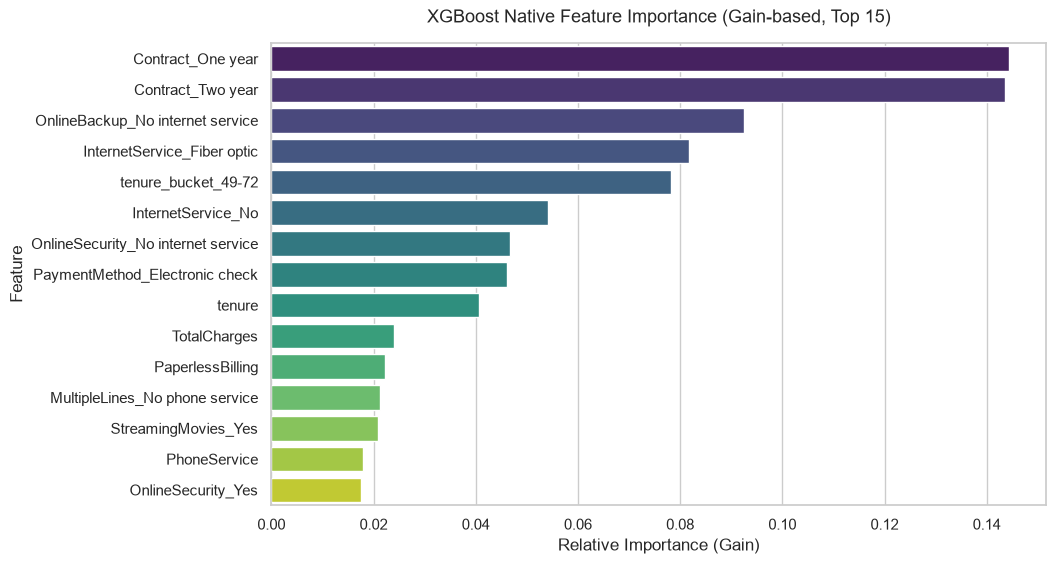

In [3]:
fig_dir = os.path.join("..", "reports", "figures")
os.makedirs(fig_dir, exist_ok=True)

# Get native importances
native_importances = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": model.feature_importances_
}).sort_values(by="Importance", ascending=False)

# Plot native importance
plt.figure(figsize=(10, 6))
sns.barplot(x="Importance", y="Feature", data=native_importances.head(15), hue="Feature", legend=False, palette="viridis")
plt.title("XGBoost Native Feature Importance (Gain-based, Top 15)", fontsize=13, pad=15)
plt.xlabel("Relative Importance (Gain)")
plt.ylabel("Feature")
plt.savefig(os.path.join(fig_dir, "11_xgb_native_importance.png"), bbox_inches='tight', dpi=150)
plt.show()

## 3. Progression 2: SHAP Global Interpretability

We calculate SHAP values using `TreeExplainer` on the same feature set that the model was trained on.

In [4]:
# Initialize explainer
explainer = shap.TreeExplainer(model)

# Calculate raw SHAP values
shap_values_raw = explainer.shap_values(X_test)

# Construct a formal shap.Explanation object
explanation = shap.Explanation(
    values=shap_values_raw,
    base_values=explainer.expected_value,
    data=X_test.values,
    feature_names=X_test.columns.tolist()
)

### Step 3.1: SHAP Global Feature Importance (Bar Plot)
Unlike gain-based native importance, SHAP magnitude measures the average absolute contribution of each feature to the model's output prediction (in log-odds space).

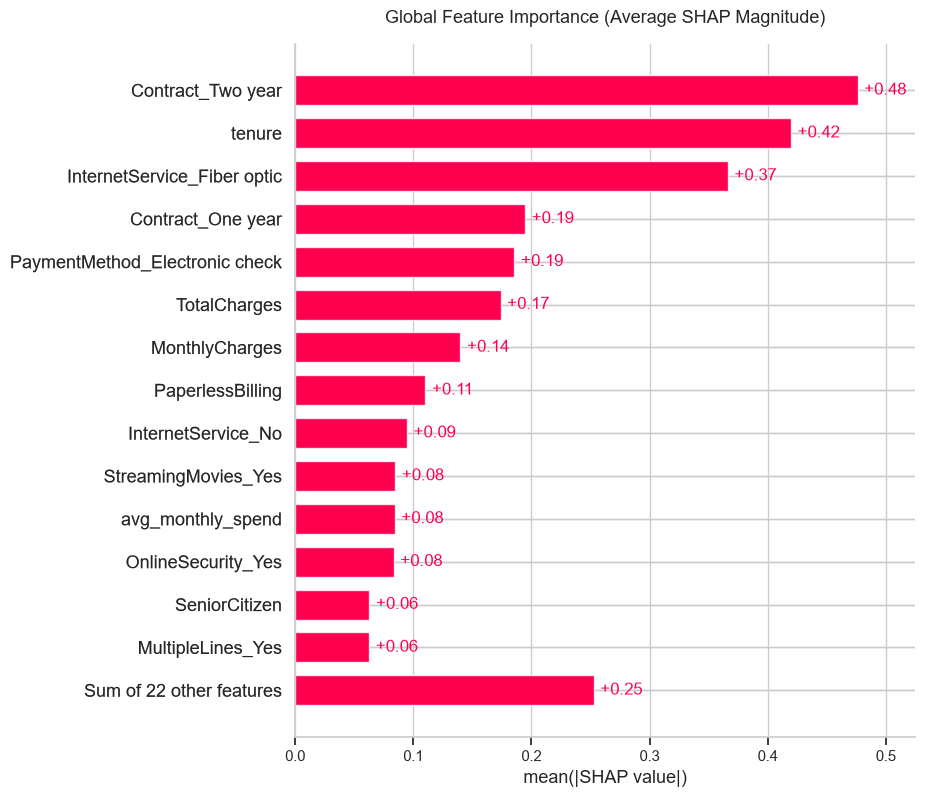

In [5]:
plt.figure(figsize=(10, 8))
shap.plots.bar(explanation, max_display=15, show=False)
plt.title("Global Feature Importance (Average SHAP Magnitude)", fontsize=13, pad=15)
plt.savefig(os.path.join(fig_dir, "11_shap_bar.png"), bbox_inches='tight', dpi=150)
plt.show()

### Step 3.2: SHAP Summary Beeswarm Plot
The beeswarm plot adds directional context. Red dots represent high values of a feature, and blue dots represent low values.

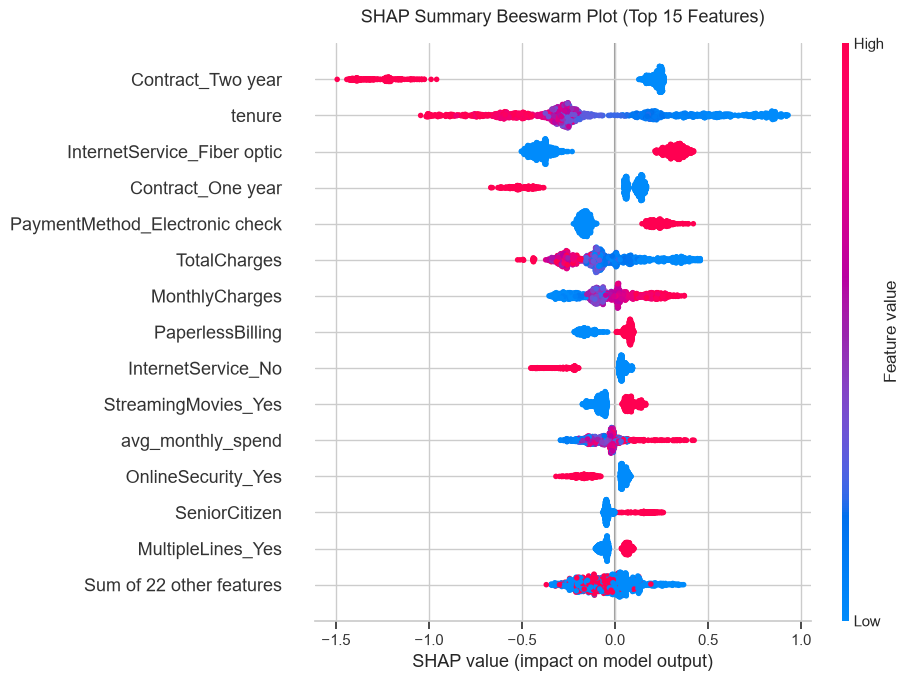

In [6]:
plt.figure(figsize=(10, 8))
shap.plots.beeswarm(explanation, max_display=15, show=False)
plt.title("SHAP Summary Beeswarm Plot (Top 15 Features)", fontsize=13, pad=15)
plt.savefig(os.path.join(fig_dir, "10_shap_summary.png"), bbox_inches='tight', dpi=150)
plt.show()

### Discrepancy Discussion: Native Importance vs. SHAP
- **The Discrepancy:** In XGBoost's native gain-based chart, categorical features like `Contract_Two year` and `InternetService_Fiber optic` are ranked as the absolute most important features. However, in the SHAP bar plot, continuous numerical variables like `tenure` and `MonthlyCharges` occupy the top spots.
- **The Explanation:** Native feature importance (Gain) is heavily biased towards features used near the root splits of trees and can over- or under-estimate continuous features depending on how deep they are split. Furthermore, native gain only measures training impurity reduction and ignores the direction of impact. 
- **Why SHAP is Superior:** SHAP values are based on cooperative game theory (Shapley values) and measure the additive marginal contribution of each feature to predictions on the test set. It treats continuous and categorical features consistently, ensuring that `tenure` (which changes continuously and has massive cumulative signal) is correctly recognized as the dominant predictor.

## 4. Progression 3: SHAP Dependence Plot

A dependence plot shows the relationship between a single feature's value (x-axis) and its corresponding SHAP value (y-axis). It helps us visualize the continuous shape of risk.

<Figure size 800x600 with 0 Axes>

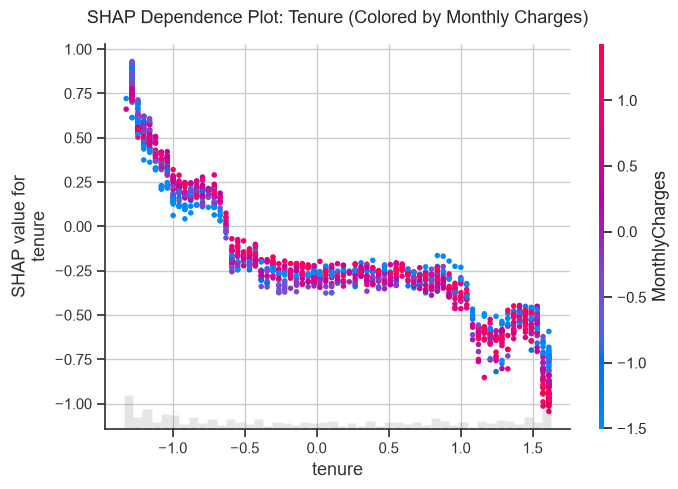

In [7]:
# Plot dependence for tenure (colored by Monthly Charges to show interactions)
plt.figure(figsize=(8, 6))
shap.plots.scatter(explanation[:, "tenure"], color=explanation[:, "MonthlyCharges"], show=False)
plt.title("SHAP Dependence Plot: Tenure (Colored by Monthly Charges)", fontsize=13, pad=15)
plt.savefig(os.path.join(fig_dir, "14_shap_dependence.png"), bbox_inches='tight', dpi=150)
plt.show()

### Dependence Plot Insights:
- **Non-Linear Risk Decay:** Churn risk decays non-linearly with tenure. The SHAP value is highly positive (high churn risk) for tenure values under 12 months, crosses the neutral line (0.0) around 20 months, and becomes strongly negative (loyal) as tenure extends past 40 months.
- **Monthly Charges Interaction:** For low tenure (0-20 months), customers with high monthly charges (red dots) have higher SHAP values than those with low monthly charges (blue dots). High pricing exacerbates early-stage churn, while long-term customers remain highly loyal regardless of high subscription costs.

## 5. Progression 4: Local Waterfall Plots (Customer Case Studies)

We investigate three specific customer profiles:
1. **High-Risk Candidate** (Probability closest to 1.0)
2. **Low-Risk Candidate** (Probability closest to 0.0)
3. **Borderline/Ambiguous Case** (Probability closest to 0.50)

In [8]:
# Get predicted probabilities on test set
y_prob = model.predict_proba(X_test)[:, 1]

# Find indices
high_risk_idx = np.argmax(y_prob)
low_risk_idx = np.argmin(y_prob)
borderline_idx = np.argmin(np.abs(y_prob - 0.50))

print(f"High-Risk Customer Index: {high_risk_idx} | Probability: {y_prob[high_risk_idx]:.4f}")
print(f"Low-Risk Customer Index: {low_risk_idx} | Probability: {y_prob[low_risk_idx]:.4f}")
print(f"Borderline Customer Index: {borderline_idx} | Probability: {y_prob[borderline_idx]:.4f}")

High-Risk Customer Index: 830 | Probability: 0.9435
Low-Risk Customer Index: 1007 | Probability: 0.0234
Borderline Customer Index: 254 | Probability: 0.5000


### Step 5.1: High-Risk Customer

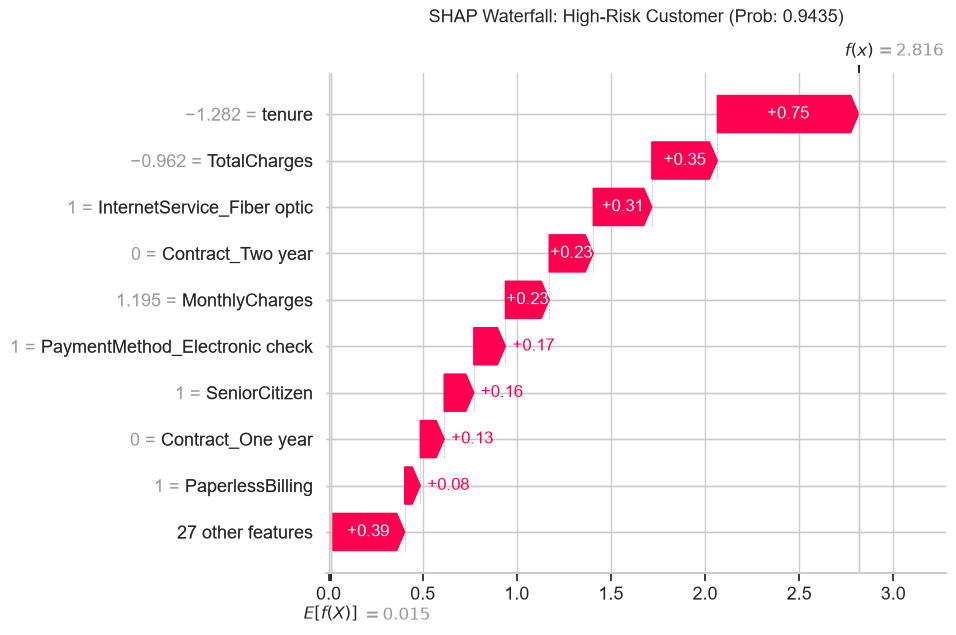

In [9]:
plt.figure(figsize=(10, 6))
shap.plots.waterfall(explanation[high_risk_idx], max_display=10, show=False)
plt.title(f"SHAP Waterfall: High-Risk Customer (Prob: {y_prob[high_risk_idx]:.4f})", fontsize=13, pad=15)
plt.savefig(os.path.join(fig_dir, "12_shap_waterfall_high.png"), bbox_inches='tight', dpi=150)
plt.show()

### Step 5.2: Low-Risk Customer

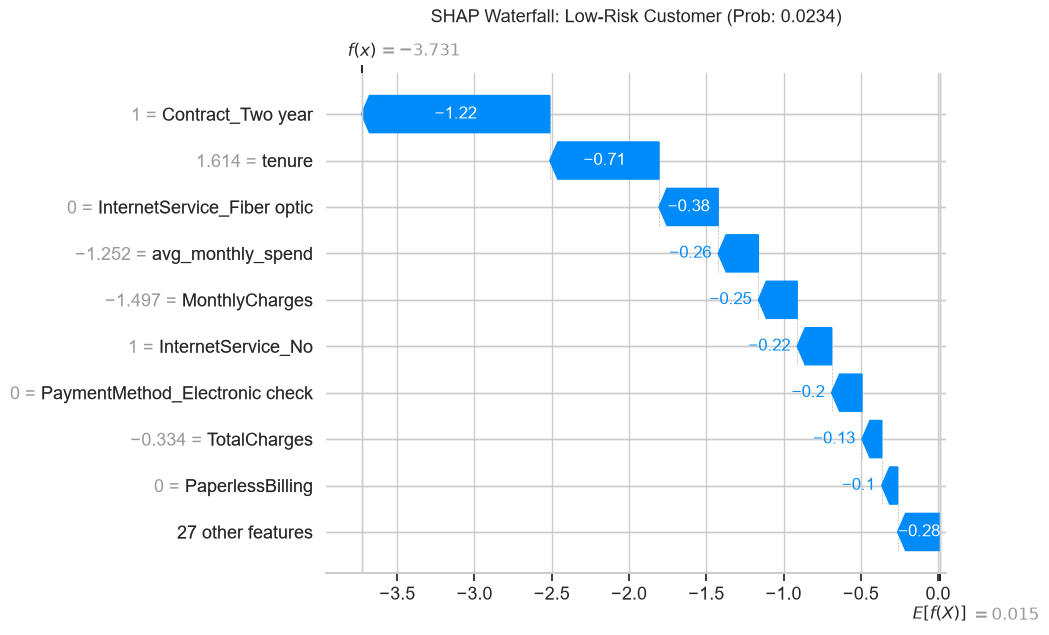

In [10]:
plt.figure(figsize=(10, 6))
shap.plots.waterfall(explanation[low_risk_idx], max_display=10, show=False)
plt.title(f"SHAP Waterfall: Low-Risk Customer (Prob: {y_prob[low_risk_idx]:.4f})", fontsize=13, pad=15)
plt.savefig(os.path.join(fig_dir, "13_shap_waterfall_low.png"), bbox_inches='tight', dpi=150)
plt.show()

### Step 5.3: Borderline Customer (Probability near 0.5)

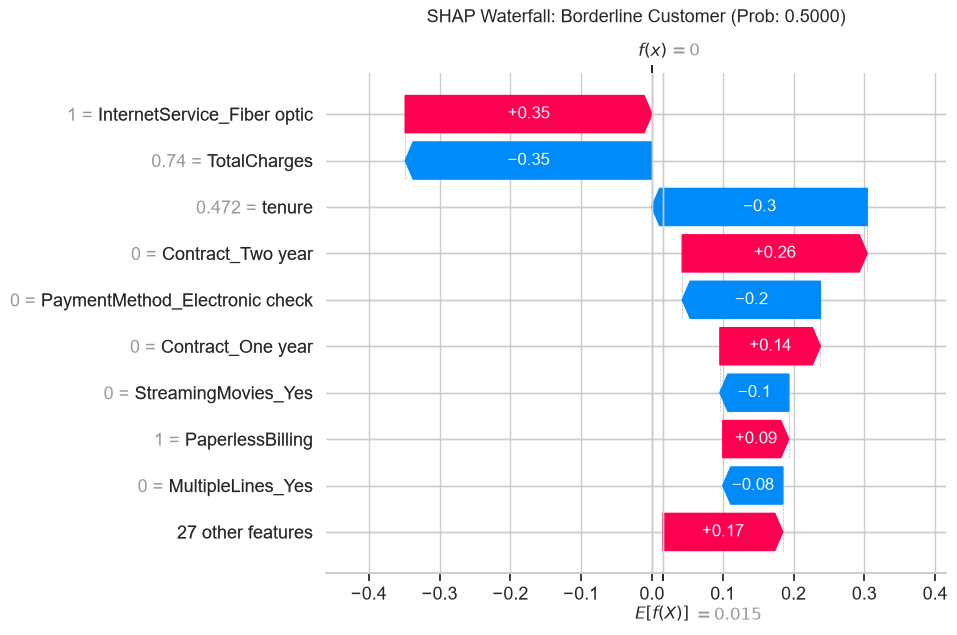

In [11]:
plt.figure(figsize=(10, 6))
shap.plots.waterfall(explanation[borderline_idx], max_display=10, show=False)
plt.title(f"SHAP Waterfall: Borderline Customer (Prob: {y_prob[borderline_idx]:.4f})", fontsize=13, pad=15)
plt.savefig(os.path.join(fig_dir, "15_shap_waterfall_borderline.png"), bbox_inches='tight', dpi=150)
plt.show()

### Local Cases Comparison & Discussion:

1. **High-Risk Case:** A very new customer (tenure is highly negative after scaling), on a Month-to-Month contract, using Fiber Optic internet, and paying via Electronic Check. All indicators point towards churn. There are no significant protective factors (blue bars) to offset this risk.

2. **Low-Risk Case:** A long-term customer (high tenure, positive scaled value), on a Two-Year contract, with automated billing (`auto_payment` = 1). The contract type and tenure pull the churn risk far below the baseline. Even if they have higher Monthly Charges, their structural loyalty features completely dominate the prediction.

3. **Borderline Case (The Tug-of-War):** This customer stands exactly at the decision boundary (~0.50 probability). 
   - **Churn Drivers (Red):** They have a month-to-month contract, a relatively high monthly charge, and use electronic check.
   - **Loyalty Drivers (Blue):** They have a decent tenure (~35 months) and subscribe to multiple add-on services (`num_services` is high). 
   - **Interpretation:** The model is weighing conflicting signals. The customer is experiencing the friction of Month-to-Month contracts and manual check payments, but their long tenure and heavy service engagement are keeping them attached. This is the **most valuable customer for targeted intervention** (e.g. offering them a discount to switch to bank transfer autopay and a 1-year contract).

## 6. Progression 5: Business Interpretations

We synthesize our global and local SHAP findings into key takeaways for business stakeholders:

- **Target the Onboarding Danger Zone:** Churn risk decays rapidly with time. The first 12 months represent a critical window. Focus onboarding support and early retention offers on customers with tenure < 12 months.
- **Mitigate Billing Friction:** Automated payment methods (`auto_payment`) significantly reduce churn risk. Running campaigns to incentivize electronic check users to switch to credit card or bank autopay (e.g., offering a one-time $10 bill credit) directly blocks churn.
- **Incentivize Contract Upgrades:** Month-to-month contract type is the single largest categorical churn driver. Moving customers to 1-year or 2-year agreements, even at a slight discount, dramatically stabilizes the customer base.
- **Audit the Fiber Optic Experience:** Fiber optic internet service shows high churn risk despite high speeds. Business teams should audit technical service delivery (outages, routers) and price satisfaction in the fiber optic segment to identify technical or pricing issues.